# 🛒 Online Retail & E-Commerce Dataset  
### AI Project | Guided for DE Students 🚀

# --- Step 0: Import Libraries ---

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

import warnings
warnings.filterwarnings('ignore')

# Setting up plot style for consistency
sns.set(style='whitegrid')
%matplotlib inline

# --- Step 1: Load the Dataset ---

In [59]:
# Replace 'path/to/synthetic_online_retail_data.csv' with your actual file path
df = pd.read_csv('https://github.com/kaopanboonyuen/SC310005_ArtificialIntelligence_2025s1/raw/main/dataset/synthetic_online_retail_data.csv')

print("Dataset loaded successfully! Here's a quick preview:")
display(df.head())

Dataset loaded successfully! Here's a quick preview:


,customer_id,order_date,product_id,category_id,category_name,product_name,quantity,price,payment_method,city,review_score,gender,age
0,13542,2024-12-17,784,10,Electronics,Smartphone,2,373.36,Credit Card,New Oliviaberg,1.0,F,56
1,23188,2024-06-01,682,50,Sports & Outdoors,Soccer Ball,5,299.34,Credit Card,Port Matthew,NaN,M,59
2,55098,2025-02-04,684,50,Sports & Outdoors,Tent,5,23.00,Credit Card,West Sarah,5.0,F,64
3,65208,2024-10-28,204,40,Books & Stationery,Story Book,2,230.11,Bank Transfer,Hernandezburgh,5.0,M,34
4,63872,2024-05-10,202,20,Fashion,Skirt,4,176.72,Credit Card,Jenkinshaven,1.0,F,33


# --- Step 2: Exploratory Data Analysis (EDA) ---

In [60]:
print("\n--- Dataset Info ---")
print(df.info())

print("\n--- Summary Statistics ---")
display(df.describe(include='all'))


--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     1000 non-null   int64  
 1   order_date      1000 non-null   object 
 2   product_id      1000 non-null   int64  
 3   category_id     1000 non-null   int64  
 4   category_name   1000 non-null   object 
 5   product_name    1000 non-null   object 
 6   quantity        1000 non-null   int64  
 7   price           1000 non-null   float64
 8   payment_method  1000 non-null   object 
 9   city            1000 non-null   object 
 10  review_score    799 non-null    float64
 11  gender          897 non-null    object 
 12  age             1000 non-null   int64  
dtypes: float64(2), int64(5), object(6)
memory usage: 101.7+ KB
None

--- Summary Statistics ---


,customer_id,order_date,product_id,category_id,category_name,product_name,quantity,price,payment_method,city,review_score,gender,age
count,1000.000000,1000,1000.000000,1000.000000,1000,1000,1000.000000,1000.000000,1000,1000,799.000000,897,1000.000000
unique,NaN,342,NaN,NaN,5,25,NaN,NaN,3,962,NaN,2,NaN
top,NaN,2024-08-12,NaN,NaN,Sports & Outdoors,Yoga Mat,NaN,NaN,Cash on Delivery,Port Matthew,NaN,M,NaN
freq,NaN,10,NaN,NaN,211,51,NaN,NaN,374,3,NaN,457,NaN
mean,55490.723000,NaN,540.726000,30.030000,NaN,NaN,2.947000,251.850660,NaN,NaN,3.992491,NaN,46.382000
std,25910.185857,NaN,261.737704,14.370303,NaN,NaN,1.413573,139.194688,NaN,NaN,1.239469,NaN,16.569992
min,10201.000000,NaN,100.000000,10.000000,NaN,NaN,1.000000,10.720000,NaN,NaN,1.000000,NaN,18.000000
25%,33857.000000,NaN,311.750000,20.000000,NaN,NaN,2.000000,128.525000,NaN,NaN,3.000000,NaN,32.000000
50%,54619.500000,NaN,542.500000,30.000000,NaN,NaN,3.000000,250.220000,NaN,NaN,4.000000,NaN,47.000000
75%,77848.500000,NaN,770.750000,40.000000,NaN,NaN,4.000000,366.467500,NaN,NaN,5.000000,NaN,61.000000


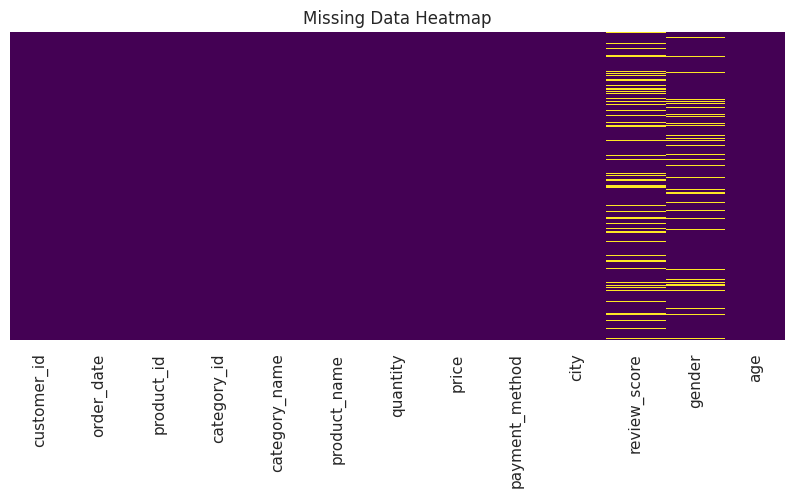

In [61]:
# Visualize missing data
plt.figure(figsize=(10, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Missing Data Heatmap')
plt.show()

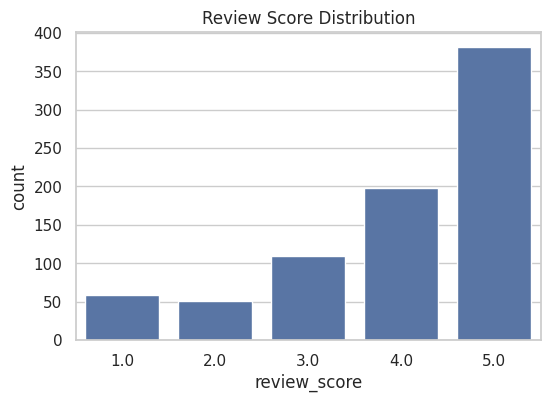

In [62]:
# Distribution of Review Scores
plt.figure(figsize=(6,4))
sns.countplot(x='review_score', data=df)
plt.title('Review Score Distribution')
plt.show()

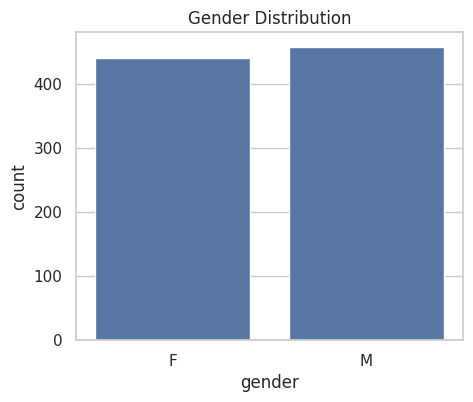

In [63]:
# Gender distribution
plt.figure(figsize=(5,4))
sns.countplot(x='gender', data=df)
plt.title('Gender Distribution')
plt.show()

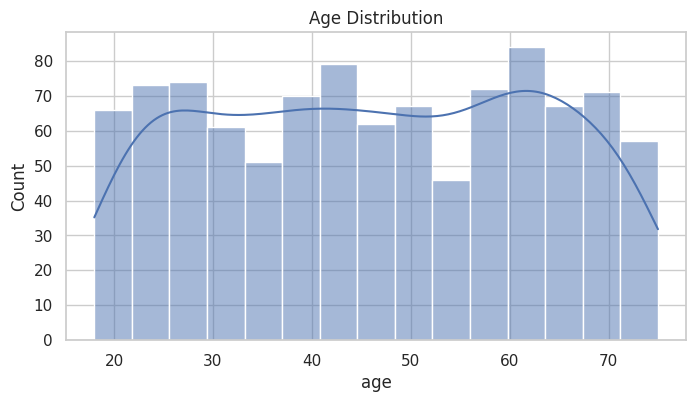

In [64]:
# Age distribution
plt.figure(figsize=(8,4))
sns.histplot(df['age'].dropna(), bins=15, kde=True)
plt.title('Age Distribution')
plt.show()

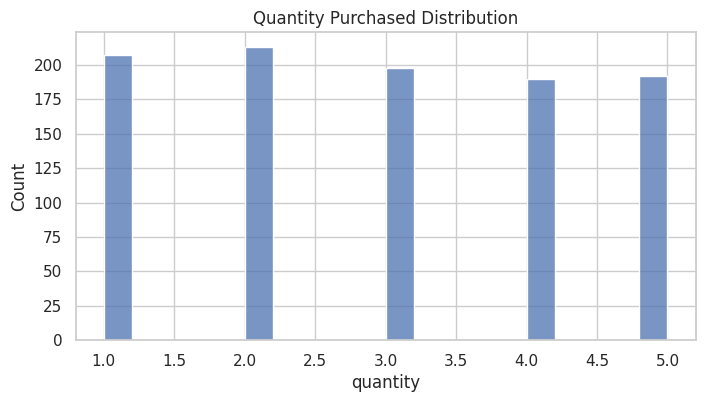

In [65]:
# Quantity distribution
plt.figure(figsize=(8,4))
sns.histplot(df['quantity'], bins=20, kde=False)
plt.title('Quantity Purchased Distribution')
plt.show()

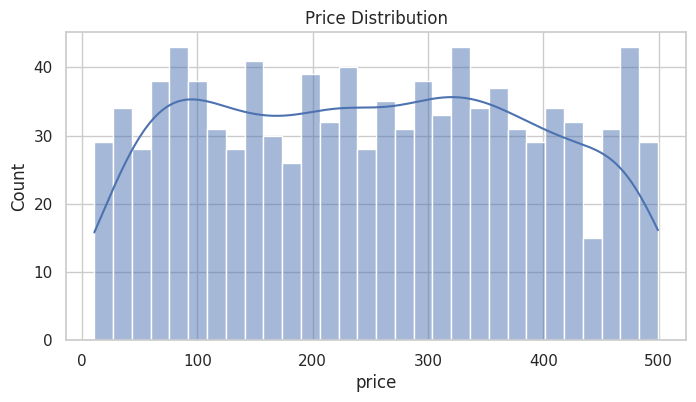

In [66]:
# Price distribution (skew check)
plt.figure(figsize=(8,4))
sns.histplot(df['price'], bins=30, kde=True)
plt.title('Price Distribution')
plt.show()


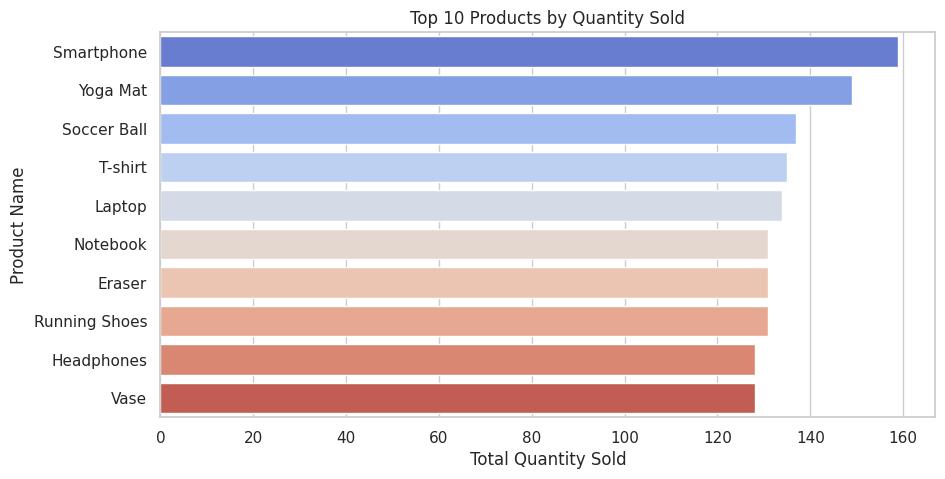

In [67]:
# Top 10 products by total quantity sold
top_products = df.groupby('product_name')['quantity'].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(10,5))
sns.barplot(x=top_products.values, y=top_products.index, palette='coolwarm')
plt.title('Top 10 Products by Quantity Sold')
plt.xlabel('Total Quantity Sold')
plt.ylabel('Product Name')
plt.show()

# --- Step 3: Data Preprocessing for Classification ---

In [68]:
# Target variable: review_score classification
# We'll create a binary classification:
#   1 (positive) if review_score >=4
#   0 (negative) if review_score <4
# Drop rows with missing review_score first
df_clean = df.dropna(subset=['review_score']).copy()
df_clean['review_class'] = (df_clean['review_score'] >= 4).astype(int)

print(f"\nNumber of samples after dropping missing reviews: {len(df_clean)}")
print("Class distribution:")
print(df_clean['review_class'].value_counts())


Number of samples after dropping missing reviews: 799
Class distribution:
review_class
1    580
0    219
Name: count, dtype: int64


In [69]:
# Fill missing values in categorical columns before encoding
df_clean['gender'] = df_clean['gender'].fillna('Unknown')
df_clean['payment_method'] = df_clean['payment_method'].fillna('Unknown')
df_clean['city'] = df_clean['city'].fillna('Unknown')

In [70]:
# Encode categorical features with LabelEncoder
le_gender = LabelEncoder()
df_clean['gender_enc'] = le_gender.fit_transform(df_clean['gender'])

le_payment = LabelEncoder()
df_clean['payment_enc'] = le_payment.fit_transform(df_clean['payment_method'])

le_category = LabelEncoder()
df_clean['category_enc'] = le_category.fit_transform(df_clean['category_name'])

le_city = LabelEncoder()
df_clean['city_enc'] = le_city.fit_transform(df_clean['city'])

In [71]:
# Prepare feature matrix X and target vector y
features = ['quantity', 'price', 'gender_enc', 'payment_enc', 'category_enc', 'city_enc', 'age']
X = df_clean[features]
y = df_clean['review_class']

In [72]:
# Check for missing values in features
print("\nMissing values in features:")
print(X.isnull().sum())


Missing values in features:
quantity        0
price           0
gender_enc      0
payment_enc     0
category_enc    0
city_enc        0
age             0
dtype: int64


In [73]:
# Fill missing ages with median (if any)
X['age'] = X['age'].fillna(X['age'].median())

# --- Step 4: Train-Test Split and Scaling ---

In [74]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale numerical features for models that need it
scaler = StandardScaler()
num_features = ['quantity', 'price', 'age']

X_train[num_features] = scaler.fit_transform(X_train[num_features])
X_test[num_features] = scaler.transform(X_test[num_features])

# --- Step 5: Define and Train Models ---

In [75]:
models = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=500, random_state=42),
    'Neural Network': MLPClassifier(hidden_layer_sizes=(50,), max_iter=1000, random_state=42)
}

results = {}

print("\n--- Training and Evaluating Models ---\n")

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    print(f"### {name} ###")
    print(classification_report(y_test, preds, digits=4))

    results[name] = {
        'accuracy': accuracy_score(y_test, preds),
        'precision': classification_report(y_test, preds, output_dict=True)['1']['precision'],
        'recall': classification_report(y_test, preds, output_dict=True)['1']['recall'],
        'f1-score': classification_report(y_test, preds, output_dict=True)['1']['f1-score']
    }


--- Training and Evaluating Models ---

### Decision Tree ###
              precision    recall  f1-score   support

           0     0.2766    0.2955    0.2857        44
           1     0.7257    0.7069    0.7162       116

    accuracy                         0.5938       160
   macro avg     0.5011    0.5012    0.5009       160
weighted avg     0.6022    0.5938    0.5978       160

### Random Forest ###
              precision    recall  f1-score   support

           0     0.2222    0.0455    0.0755        44
           1     0.7219    0.9397    0.8165       116

    accuracy                         0.6937       160
   macro avg     0.4720    0.4926    0.4460       160
weighted avg     0.5845    0.6937    0.6127       160

### Logistic Regression ###
              precision    recall  f1-score   support

           0     0.0000    0.0000    0.0000        44
           1     0.7250    1.0000    0.8406       116

    accuracy                         0.7250       160
   macro avg   

# --- Step 6: Visualize Model Performance ---

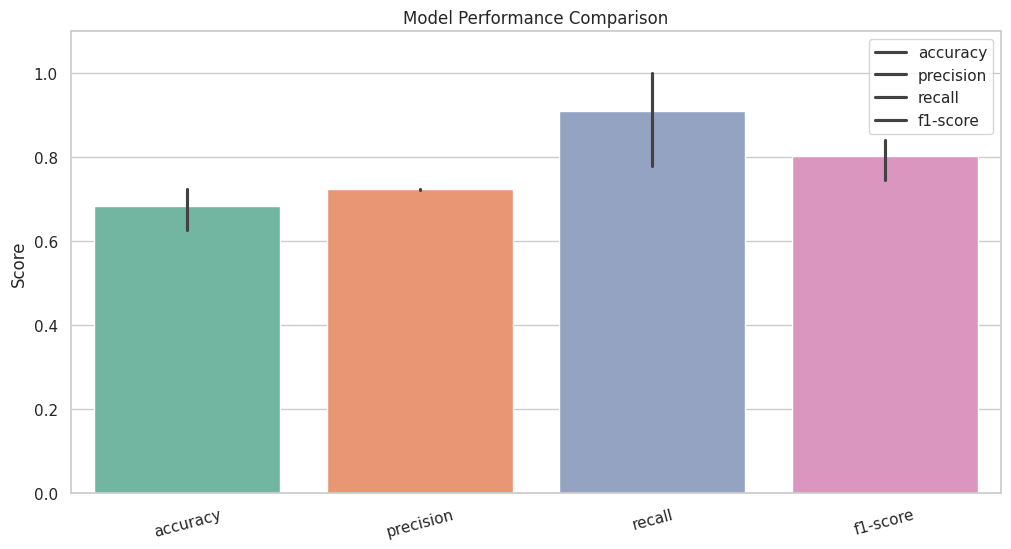

In [76]:
metrics = ['accuracy', 'precision', 'recall', 'f1-score']
results_df = pd.DataFrame(results).T[metrics]

plt.figure(figsize=(12,6))
sns.barplot(data=results_df, palette='Set2')
plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.ylim(0, 1.1)
plt.legend(labels=metrics, loc='upper right')
plt.xticks(rotation=15)
plt.show()

# --- Step 7: Insights and Winner Model ---


In [77]:
winner = results_df['f1-score'].idxmax()
print(f"\n🎉 The best model based on F1-score is: {winner}")


🎉 The best model based on F1-score is: Logistic Regression


# --- Step 8: Explain Model Predictions Using LIME ---

In [78]:
!pip install lime --q

Prediction probabilities for test instance 5: [0.44 0.56]
True class: 1

LIME Explanation (Feature contributions):
price <= -0.86: -0.0692
city_enc > 583.50: -0.0320
0.04 < age <= 0.88: -0.0291
0.00 < gender_enc <= 1.00: 0.0253
2.00 < category_enc <= 3.00: -0.0222
1.00 < payment_enc <= 2.00: -0.0169


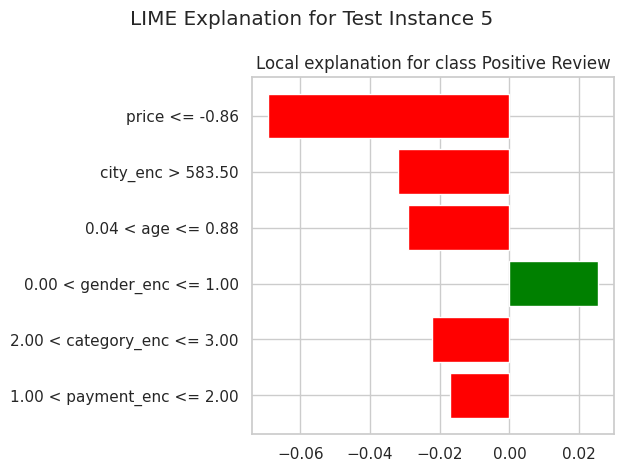

In [79]:
# Install lime if not installed (uncomment if needed)
# !pip install lime

from lime.lime_tabular import LimeTabularExplainer

# We'll explain the Random Forest model (usually a strong performer)
explainer = LimeTabularExplainer(
    training_data=np.array(X_train),
    feature_names=features,
    class_names=['Negative Review','Positive Review'],
    mode='classification'
)

# Select a test instance to explain
i = 5  # You can change this index to explain different samples
test_instance = X_test.iloc[i].values.reshape(1, -1)

# Get model prediction probabilities
rf_model = models['Random Forest']
pred_probs = rf_model.predict_proba(test_instance)[0]

print(f"Prediction probabilities for test instance {i}: {pred_probs}")
print(f"True class: {y_test.iloc[i]}")

# Generate explanation
exp = explainer.explain_instance(
    data_row=X_test.iloc[i],
    predict_fn=rf_model.predict_proba,
    num_features=6
)

# Show explanation as a list
print("\nLIME Explanation (Feature contributions):")
for feature, weight in exp.as_list():
    print(f"{feature}: {weight:.4f}")

# Visualize explanation
fig = exp.as_pyplot_figure()
fig.suptitle(f'LIME Explanation for Test Instance {i}')
plt.tight_layout()
plt.show()